# Features, Logistic Regression and kNN

**Owner:** Puneet (pixel/HOG features, Logistic Regression, kNN).

This notebook follows one raw image through both representations, checks the feature
contract on real fit images, shows how the four LR/kNN rows were tuned and frozen,
recomputes their validation metrics from the saved prediction files, and refits the
frozen LR rows to measure how closely a fresh fit reproduces those predictions.

Only the official training partition (48,000 fit / 12,000 validation) is used here.
The official test set is not loaded. Frozen records and predictions are read, never written.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage import exposure
from skimage.feature import hog
from threadpoolctl import threadpool_limits

from clothing_ml.data import CLASS_NAMES, load_official
from clothing_ml.evaluate import label_metrics, predict_batches, validate_predictions
from clothing_ml.features import HOG_SETTINGS, cached_features, make_features, normalized_images
from clothing_ml.models import make_model
from clothing_ml.utils import ROOT, read_json

images, labels = load_official("train")
with np.load(ROOT / "data/full_indices.npz") as indices:
    fit_ids, val_ids = indices["train_idx"], indices["val_idx"]
freeze = read_json(ROOT / "results/full/freeze.json")
rows = {(r["feature"], r["model"]): r for r in freeze["finalists"] if r["model"] in {"lr", "knn"}}
print(f"fit images: {len(fit_ids):,}  validation images: {len(val_ids):,}  overlap: {np.intersect1d(fit_ids, val_ids).size}")
print("frozen LR/kNN rows:", {f"{f}+{m}": r["parameters"] for (f, m), r in rows.items()})

fit images: 48,000  validation images: 12,000  overlap: 0
frozen LR/kNN rows: {'pixels+lr': {'C': 0.1}, 'pixels+knn': {'n_neighbors': 5}, 'hog+lr': {'C': 0.1}, 'hog+knn': {'n_neighbors': 5}}


## 1. One image, two representations

Feature functions take raw `uint8` images of shape `(N, 28, 28)`. Dividing by 255 is a fixed
conversion that learns nothing from data. Flattening keeps every value in row-major order;
HOG summarises local edge directions with a rule fixed before any label is seen.

sample_id 50398 (official_train), label 6 = Shirt
raw: shape (28, 28), dtype uint8, range 0-255
pixels: 784 values, dtype float32, range 0.000-1.000
hog: 1296 values, dtype float32, range 0.000-0.607


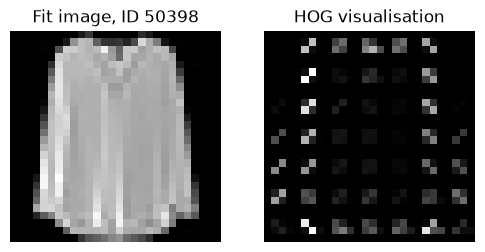

In [2]:
sample_id = int(fit_ids[0])
raw = images[sample_id:sample_id + 1]
pixels = make_features(raw, "pixels")[0]
hog_vector = make_features(raw, "hog")[0]
print(f"sample_id {sample_id} (official_train), label {labels[sample_id]} = {CLASS_NAMES[labels[sample_id]]}")
print(f"raw: shape {raw.shape[1:]}, dtype {raw.dtype}, range {raw.min()}-{raw.max()}")
print(f"pixels: {pixels.shape[0]} values, dtype {pixels.dtype}, range {pixels.min():.3f}-{pixels.max():.3f}")
print(f"hog: {hog_vector.shape[0]} values, dtype {hog_vector.dtype}, range {hog_vector.min():.3f}-{hog_vector.max():.3f}")

_, picture = hog(normalized_images(raw)[0], visualize=True, **HOG_SETTINGS)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(raw[0], cmap="gray", vmin=0, vmax=255)
ax[0].set_title(f"Fit image, ID {sample_id}")
ax[1].imshow(exposure.rescale_intensity(picture, in_range="image"), cmap="gray")
ax[1].set_title("HOG visualisation")
for a in ax:
    a.axis("off")
plt.show()

The HOG picture illustrates edge-direction structure; it is not the feature vector itself and
does not show what any classifier learned.

## 2. Feature dimensions

HOG is longer than the pixel vector because 2×2-cell blocks overlap by one cell.

In [3]:
cells = 28 // HOG_SETTINGS["pixels_per_cell"][0]
blocks = cells - HOG_SETTINGS["cells_per_block"][0] + 1
per_block = int(np.prod(HOG_SETTINGS["cells_per_block"])) * HOG_SETTINGS["orientations"]
table = pd.DataFrame([
    {"representation": "pixels", "derivation": "28 x 28", "dimension": 28 * 28},
    {"representation": "HOG", "derivation": f"{blocks} x {blocks} blocks x {per_block} (2x2 cells x 9 bins)",
     "dimension": blocks * blocks * per_block},
])
table["bytes per image (float32)"] = table.dimension * 4
table["48,000-row matrix (MiB)"] = (table.dimension * 4 * len(fit_ids) / 2**20).round(1)
assert table.dimension.tolist() == [pixels.size, hog_vector.size]
table

,representation,derivation,dimension,bytes per image (float32),"48,000-row matrix (MiB)"
0,pixels,28 x 28,784,3136,143.6
1,HOG,6 x 6 blocks x 36 (2x2 cells x 9 bins),1296,5184,237.3


## 3. Feature contract on real fit images

Each feature row must depend only on its own image, so a one-image call, a batch call and a
shuffled batch must agree row by row, and repeated calls must be identical.

In [4]:
check_ids = fit_ids[:200]
for name in ["pixels", "hog"]:
    batch = make_features(images[check_ids], name)
    single = np.vstack([make_features(images[i:i + 1], name) for i in check_ids[:20]])
    order = np.random.default_rng(42).permutation(len(check_ids))
    shuffled = make_features(images[check_ids[order]], name)
    assert np.isfinite(batch).all()
    assert np.array_equal(batch[:20], single)
    assert np.array_equal(shuffled, batch[order])
    assert np.array_equal(batch, make_features(images[check_ids], name))
    print(f"{name}: {batch.shape} finite, deterministic, batch == single == shuffled")

pixels: (200, 784) finite, deterministic, batch == single == shuffled


hog: (200, 1296) finite, deterministic, batch == single == shuffled


## 4. Validation tuning and freeze

Candidates were compared on the shared 12,000-image budget fit subset and the 12,000-image
validation partition. The selection rule, fixed before test access, is validation macro F1,
then accuracy, then validation prediction time, then run ID. The chosen settings were then
fitted on all 48,000 fit images.

In [5]:
candidates = []
for path in sorted((ROOT / "results/budget/records").glob("budget_*_*.json")):
    record = read_json(path)
    if record["model"] in {"lr", "knn"}:
        candidates.append({"run_id": record["run_id"], "feature": record["feature"], "model": record["model"],
                           "parameters": json.dumps(record["parameters"]), "train_n": record["train_n"],
                           "val_macro_f1": round(record["macro_f1"], 4), "val_accuracy": round(record["accuracy"], 4),
                           "converged": record["converged"], "warnings": len(record["warnings"])})
budget_freeze = {r["run_id"] for r in read_json(ROOT / "results/budget/freeze.json")["finalists"]}
frame = pd.DataFrame(candidates)
frame["selected"] = frame.run_id.isin(budget_freeze)
frame.drop(columns="run_id").sort_values(["model", "feature", "val_macro_f1"], ascending=[True, True, False]).reset_index(drop=True)

,feature,model,parameters,train_n,val_macro_f1,val_accuracy,converged,warnings,selected
0,hog,knn,"{""n_neighbors"": 5}",12000,0.8540,0.8546,True,0,True
1,hog,knn,"{""n_neighbors"": 3}",12000,0.8501,0.8503,True,0,False
2,pixels,knn,"{""n_neighbors"": 5}",12000,0.8346,0.8347,True,0,True
3,pixels,knn,"{""n_neighbors"": 3}",12000,0.8320,0.8316,True,0,False
4,hog,lr,"{""C"": 0.1}",12000,0.8540,0.8538,True,0,True
5,hog,lr,"{""C"": 1.0}",12000,0.8385,0.8382,True,0,False
6,pixels,lr,"{""C"": 0.1}",12000,0.8375,0.8376,True,0,True
7,pixels,lr,"{""C"": 1.0}",12000,0.8083,0.8079,True,0,False


Smaller `C` means stronger regularisation; `C=0.1` won for both representations. For kNN,
`k=5` beat `k=3` with distance weighting on both. Every attempted LR configuration converged
without warnings. The grids are deliberately small, so these are validated choices, not
global optima.

## 5. Recompute validation metrics from saved predictions

In [6]:
summary = []
for (feature, model), row in sorted(rows.items(), key=lambda item: (item[0][1], item[0][0])):
    saved = pd.read_csv(ROOT / f"results/full/predictions/{row['run_id']}_val.csv.gz")
    saved = validate_predictions(saved, val_ids, labels, "val", row["run_id"])
    metrics = label_metrics(saved.y_true, saved.y_pred)
    assert np.isclose(metrics["accuracy"], row["accuracy"]) and np.isclose(metrics["macro_f1"], row["macro_f1"])
    summary.append({"model": model, "feature": feature, "parameters": json.dumps(row["parameters"]),
                    "train_n": row["train_n"], "val_accuracy": round(metrics["accuracy"], 4),
                    "val_macro_f1": round(metrics["macro_f1"], 4),
                    **{CLASS_NAMES[c]: round(r, 3) for c, r in enumerate(metrics["recall"])}})
validation = pd.DataFrame(summary)
validation[["model", "feature", "parameters", "train_n", "val_accuracy", "val_macro_f1"]]

,model,feature,parameters,train_n,val_accuracy,val_macro_f1
0,knn,hog,"{""n_neighbors"": 5}",48000,0.8756,0.8749
1,knn,pixels,"{""n_neighbors"": 5}",48000,0.8584,0.8585
2,lr,hog,"{""C"": 0.1}",48000,0.8832,0.8834
3,lr,pixels,"{""C"": 0.1}",48000,0.8596,0.8590


In [7]:
recall_columns = list(CLASS_NAMES)
change = []
for model in ["lr", "knn"]:
    pix = validation[(validation.model == model) & (validation.feature == "pixels")].iloc[0]
    hg = validation[(validation.model == model) & (validation.feature == "hog")].iloc[0]
    delta = (hg[recall_columns] - pix[recall_columns]).astype(float) * 100
    change.append({"model": model, "macro F1 change (pp)": round((hg.val_macro_f1 - pix.val_macro_f1) * 100, 2),
                   "largest recall gain": f"{delta.idxmax()} {delta.max():+.1f} pp",
                   "largest recall loss": f"{delta.idxmin()} {delta.min():+.1f} pp"})
pd.DataFrame(change)

,model,macro F1 change (pp),largest recall gain,largest recall loss
0,lr,2.44,Shirt +8.5 pp,Sandal -0.4 pp
1,knn,1.64,Sandal +7.4 pp,Bag -0.8 pp


Under the same split and 48,000-image training size, HOG raised validation macro F1 for both
LR and kNN. The per-class columns show whether that aggregate gain hides a weaker category.
These are single-split differences, not significance tests.

## 6. Complexity

In [8]:
complexity = []
for (feature, model), row in sorted(rows.items(), key=lambda item: (item[0][1], item[0][0])):
    c = row["complexity"]
    complexity.append({"model": model, "feature": feature, "dimension": row["feature_dim"],
                       "measure": c["complexity_type"], "value": c["complexity_value"],
                       "scaler statistics": c["scaler_stored_mean_scale_scalars"],
                       "serialized bytes": row["serialized_bytes"]})
    if model == "lr":
        assert c["complexity_value"] == 10 * (row["feature_dim"] + 1)
pd.DataFrame(complexity)

,model,feature,dimension,measure,value,scaler statistics,serialized bytes
0,knn,hog,1296,stored training feature scalars (not learned w...,62208000,2592,154424671
1,knn,pixels,784,stored training feature scalars (not learned w...,37632000,0,32614887
2,lr,hog,1296,learned classifier coefficient and intercept s...,12970,2592,80201
3,lr,pixels,784,learned classifier coefficient and intercept s...,7850,1568,49125


LR stores `10(d+1)` learned scalars. kNN learns no coefficient vector: it stores all 48,000 fit
rows and searches them at prediction time, so its small fit time is not a cheap-inference claim.

## 7. Refit the frozen LR rows and trace one validation image

Model artifacts are not committed, so this refits both frozen LR pipelines on the 48,000 fit IDs
(single thread, as in the original run) and compares every validation prediction to the saved file.
The saved predictions remain the frozen evidence; this checks that the recipe, not a stored binary,
produces them.

In [9]:
trace_id = int(val_ids[0])
for feature in ["pixels", "hog"]:
    row = rows[(feature, "lr")]
    Xfit, _ = cached_features(images[fit_ids], fit_ids, "official_train", feature)
    Xval, _ = cached_features(images[val_ids], val_ids, "official_train", feature)
    with threadpool_limits(limits=1):
        start = time.perf_counter()
        pipe = make_model("lr", feature, row["parameters"]).fit(Xfit, labels[fit_ids])
        seconds = time.perf_counter() - start
        refit = predict_batches(pipe, Xval)
    saved = pd.read_csv(ROOT / f"results/full/predictions/{row['run_id']}_val.csv.gz")
    saved = validate_predictions(saved, val_ids, labels, "val", row["run_id"])
    matches = int((refit == saved.y_pred.to_numpy()).sum())
    refit_f1 = label_metrics(labels[val_ids], refit)["macro_f1"]
    one = pipe.predict(make_features(images[trace_id:trace_id + 1], feature))[0]
    print(f"{row['run_id']}: refit in {seconds:.1f}s; {matches:,}/{len(val_ids):,} validation predictions match saved; "
          f"macro F1 refit {refit_f1:.4f} vs saved {row['macro_f1']:.4f}")
    print(f"  trace: val ID {trace_id}, true {CLASS_NAMES[labels[trace_id]]} -> {feature} features "
          f"{make_features(images[trace_id:trace_id + 1], feature).shape} -> predicted {CLASS_NAMES[one]}")

full_pixels_lr_580addbb: refit in 19.5s; 11,949/12,000 validation predictions match saved; macro F1 refit 0.8591 vs saved 0.8590
  trace: val ID 37343, true Sandal -> pixels features (1, 784) -> predicted Sandal


full_hog_lr_580addbb: refit in 12.4s; 11,983/12,000 validation predictions match saved; macro F1 refit 0.8832 vs saved 0.8834
  trace: val ID 37343, true Sandal -> hog features (1, 1296) -> predicted Sandal


A fresh LBFGS fit can land a few borderline validation images on the other side of a decision
boundary, so agreement is near-complete rather than exact; the printed macro F1 values show the
practical effect. Different BLAS builds and floating-point summation order are the likely cause.
kNN has no iterative optimiser, and its refit in section 8 matches every saved prediction.

## 8. Why kNN gets garments wrong

`scripts/knn_neighbours.py` refits both frozen kNN rows, confirms they reproduce all 12,000 saved
validation predictions, and retrieves the five nearest fit images for every validation error.

In [10]:
neighbours = read_json(ROOT / "figures/full/knn_neighbours.json")
pd.DataFrame([{"feature": f, "validation errors": r["validation_errors"],
               "majority of neighbours carry predicted label": r["errors_with_majority_of_neighbours_carrying_predicted_label"],
               "no neighbour carries true label": r["errors_with_no_neighbour_carrying_true_label"],
               "most frequent pair": f"{r['most_frequent_error_pairs'][0]['true']} -> {r['most_frequent_error_pairs'][0]['predicted']}"}
              for f, r in neighbours["rows"].items()])

,feature,validation errors,majority of neighbours carry predicted label,no neighbour carries true label,most frequent pair
0,pixels,1699,1452,514,Shirt -> T-shirt/top
1,hog,1493,1265,429,Shirt -> T-shirt/top


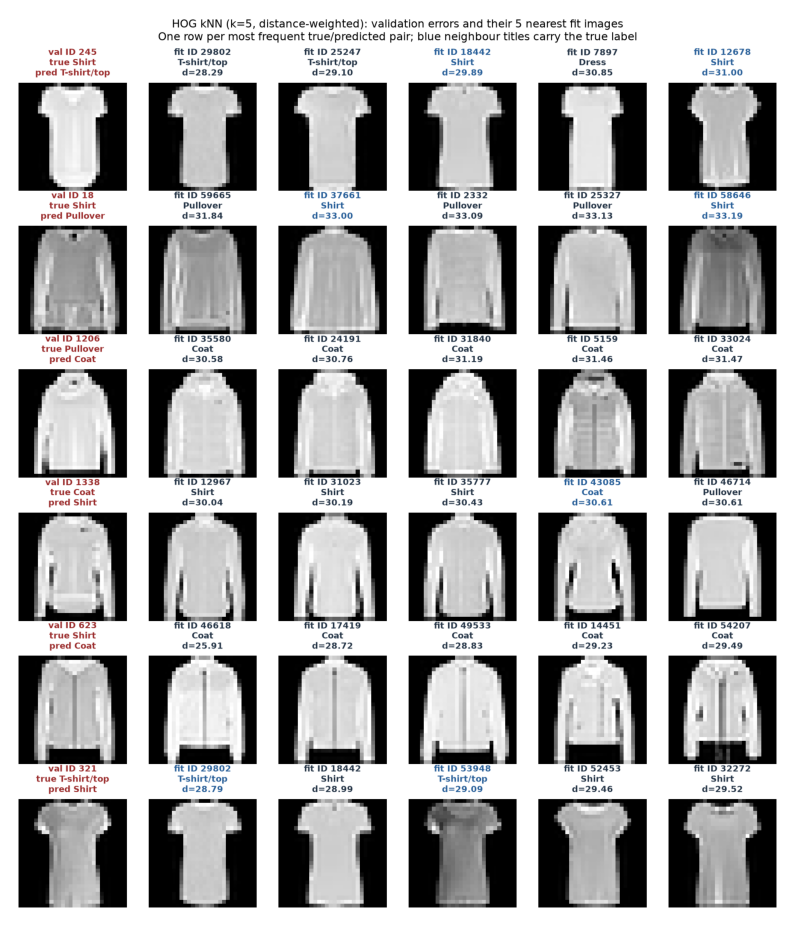

In [11]:
plt.figure(figsize=(10, 12))
plt.imshow(plt.imread(ROOT / "figures/full/knn_neighbours_hog.png"))
plt.axis("off")
plt.show()

Most errors are outvoted rather than coin flips: the majority of the five nearest fit images
already carry the wrong label, mostly among Shirt, T-shirt/top, Pullover and Coat. The panel
shows one example per frequent pair; the counts above cover every validation error. Visual
similarity suggests a reason but does not prove one, and it does not establish label noise.

## Limitations and Phase 2

- One fixed HOG configuration and small LR/kNN grids; no `C=10`, `k=7` or uniform weighting.
- A single validation split; differences are not significance-tested.
- Both representations are fixed before training. A CNN that learns its own local filters is
  the Phase 2 comparison, evaluated on this same split.